Examen finale: Sahel Mobile
Sahel Mobile : analyse de la résiliation des abonnés
Sahel Mobile est un opérateur de télécommunications comptant plus de 7 000 abonnés. Plus d'un quart d'entre eux résilient.
Nous devons comprendre qui résilie, à quel moment et pourquoi, puis construire un tableau de bord interactif pour les chefs de produit.

In [39]:
!pip install pandas numpy matplotlib seaborn streamlit plotly

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Q1.1 Chargez le fichier data/Projet_2_Sahel_Mobile.csv dans un
DataFrame nommé df.

In [41]:
 # Acces Googledrive
from google.colab import drive
drive.mount('/content/drive')
import os
print('📁 Répertoire actuel :', os.getcwd())
print('📄 Fichiers présents :', os.listdir('/content/drive/MyDrive/Colab Notebooks/Data'))
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Data/projet2_telco_churn.csv')
df_brut = df.copy()
print(f"✅ Dataset chargé : {df.shape[0]} lignes × {df.shape[1]} colonnes")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 Répertoire actuel : /content
📄 Fichiers présents : ['projet2_telco_churn.csv', 'Projet_2_Sahel_Mobile.docx']
✅ Dataset chargé : 7043 lignes × 21 colonnes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


J’ai chargé les 7 043 abonnés dans un DataFrame df. Chaque ligne est un abonné et chaque colonne une information. La colonne Churn indique s’il a résilié

Q1.2 Vérifions le type de chaque colonne

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


TotalCharges est stockée en texte alors que c'est un montant, ce qui empêche tout calcul, et SeniorCitizen` est codée en 0/1 alors que les autres colonnes Oui/Non utilisent "Yes"/"No".

Partie 2_Diagnostic qualité et nettoyage

Q2.1 Valeurs manquantes

Je vérifie les valeurs manquantes parce qu’une case vide peut fausser une moyenne ou faire planter un calcul

In [43]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Problème 1. TotalCharges devrait etre en nombre pas en texte

In [44]:
lignes_aberrantes = df_brut[df_brut["TotalCharges"].str.strip() == ""]
print(f"Nombre de lignes aberrantes : {len(lignes_aberrantes)}")
print("Valeurs de tenure pour ces lignes :", lignes_aberrantes["tenure"].unique())
print(lignes_aberrantes)

Nombre de lignes aberrantes : 11
Valeurs de tenure pour ces lignes : [0]
      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
488   4472-LVYGI  Female              0     Yes        Yes       0   
753   3115-CZMZD    Male              0      No        Yes       0   
936   5709-LVOEQ  Female              0     Yes        Yes       0   
1082  4367-NUYAO    Male              0     Yes        Yes       0   
1340  1371-DWPAZ  Female              0     Yes        Yes       0   
3331  7644-OMVMY    Male              0     Yes        Yes       0   
3826  3213-VVOLG    Male              0     Yes        Yes       0   
4380  2520-SGTTA  Female              0     Yes        Yes       0   
5218  2923-ARZLG    Male              0     Yes        Yes       0   
6670  4075-WKNIU  Female              0     Yes        Yes       0   
6754  2775-SEFEE    Male              0      No        Yes       0   

     PhoneService     MultipleLines InternetService       OnlineSecurity  ...  \
488  

In [45]:
print(lignes_aberrantes[["customerID", "tenure", "TotalCharges"]])

      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             
3331  7644-OMVMY       0             
3826  3213-VVOLG       0             
4380  2520-SGTTA       0             
5218  2923-ARZLG       0             
6670  4075-WKNIU       0             
6754  2775-SEFEE       0             


TotalCharges contient 11 cases vides que isnull()` ne détecte pas, et ces 11 abonnés ont tous une ancienneté de 0 mois : ils viennent de s'inscrire et n'ont pas encore été facturés. Je ne les supprime pas et je remplace la case vide par 0



In [46]:
df["TotalCharges"] = df["TotalCharges"].str.strip().replace("", "0").astype(float)
df["TotalCharges"].dtype

dtype('float64')

Problème 2: Senior citizen codé 0 alors que les autres colonnes oui/non utilisent "Yes"/"No". Je l'ai convertie (0 devient "No", 1 devient "Yes") pour harmoniser



In [47]:
df["SeniorCitizen"].unique()

array([0, 1])

In [48]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

In [49]:
df["SeniorCitizen"].unique()

array(['No', 'Yes'], dtype=object)

Problèmes d'option au niveau des colonnes

In [50]:
df["OnlineSecurity"].unique()

array(['No', 'Yes', 'No internet service'], dtype=object)

In [51]:
colonnes_options = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                     "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines"]
for col in colonnes_options:
    df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})
    print(f"{col:18s}", sorted(df[col].unique()))

OnlineSecurity     ['No', 'Yes']
OnlineBackup       ['No', 'Yes']
DeviceProtection   ['No', 'Yes']
TechSupport        ['No', 'Yes']
StreamingTV        ['No', 'Yes']
StreamingMovies    ['No', 'Yes']
MultipleLines      ['No', 'Yes']


J’ai fait une liste des 7 colonnes concernées. Pour chacune, j’ai remplacé “No internet service” et “No phone service” par “No”, puis j’ai vérifié qu’il ne restait que “No” et “Yes”

In [52]:
df["OnlineSecurity"].unique()

array(['No', 'Yes'], dtype=object)

Vérifions les doublons

Lignes entièrement identiques

In [53]:
nb_doublons=df.duplicated().sum()
print(f'il y a des lignes dupliquées: {nb_doublons}')

il y a des lignes dupliquées: 0


Identifiants clients répétés : un abonné ne doit apparaître qu'une fois


In [54]:
print("customerID dupliqués :", df["customerID"].duplicated().sum())

customerID dupliqués : 0


Aucune ligne dupliquée et aucun customerIDen double : chaque abonné apparaît une seule fois. Aucune suppression n'était nécessaire

Analyse globale: Vérification

In [55]:
print("TotalCharges type     :", df["TotalCharges"].dtype)
print("SeniorCitizen valeurs :", df["SeniorCitizen"].unique())
print("Valeurs manquantes    :", df.isnull().sum().sum())
print("Doublons              :", df.duplicated().sum())

TotalCharges type     : float64
SeniorCitizen valeurs : ['No' 'Yes']
Valeurs manquantes    : 0
Doublons              : 0


## Partie 3 : Analyse descriptive et visualisation

### 3.1 Taux de résiliation global

In [56]:
taux_churn = (df["Churn"] == "Yes").mean()
print(f"Taux de résiliation global : {taux_churn:.1%}")
print(f"Abonnés partis : {(df['Churn'] == 'Yes').sum()} sur {len(df)}")

Taux de résiliation global : 26.5%
Abonnés partis : 1869 sur 7043


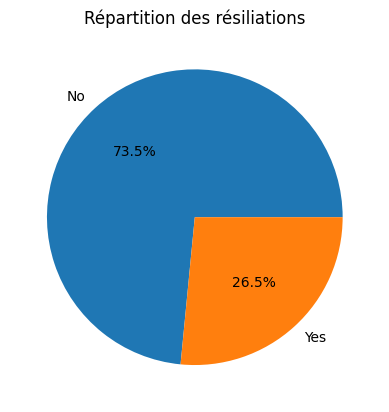

In [57]:
df["Churn"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Répartition des résiliations")
plt.ylabel("")
plt.show()

1 869 abonnés sur 7 043 ont résilié, soit 26,5 %, environ 1 sur 4. Je cherche quels groupes d'abonnés résilient plus que cette moyenne.

### 3.2 Distribution de l'ancienneté : abonnés restés et partis

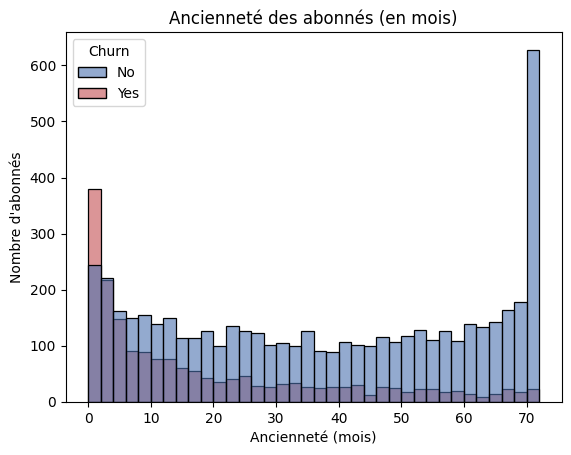

       mean  median
Churn              
No     37.6    38.0
Yes    18.0    10.0


In [58]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, alpha=0.6,
             palette={"No": "#4C72B0", "Yes": "#C44E52"})

plt.title("Ancienneté des abonnés (en mois)")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Nombre d'abonnés")
plt.show()

# Ancienneté moyenne et médiane de chaque groupe
print(df.groupby("Churn")["tenure"].agg(["mean", "median"]).round(1))

Les abonnés qui résilient ont une ancienneté médiane de 10 mois, contre 38 mois pour ceux qui restent : ils partent surtout au début de leur abonnement.

### 3.3 Facture mensuelle : abonnés restés et partis



In [59]:
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

# Moyenne de tous les abonnés (pour comparer)
print("Moyenne de tous les abonnés :", round(df["MonthlyCharges"].mean(), 2))

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64
Moyenne de tous les abonnés : 64.76


Les abonnés qui résilient paient en moyenne 74,44 par mois, contre 61 pour ceux qui restent.



### Question 1 : Les abonnés en contrat mensuel résilient-ils davantage ?

#### Étape 1 : calculer le taux de résiliation par type de contrat

In [60]:
contract_churn = df.groupby("Contract")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(contract_churn)

ecart = contract_churn["Month-to-month"] - contract_churn["Two year"]
print(f"Écart mensuel - biannuel : {ecart:.1f} points")

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64
Écart mensuel - biannuel : 39.9 points


le taux de résiliation est de 42,7 % pour le contrat mensuel, 11,3 % pour l'annuel et 2,8 % pour le biannuel. Plus l'engagement est long, moins les abonnés résilient. L'écart entre mensuel et biannuel est de 39,9 points. Le type de contrat est un facteur très fort de résiliation.

#### Visualisation : taux de résiliation par type de contrat

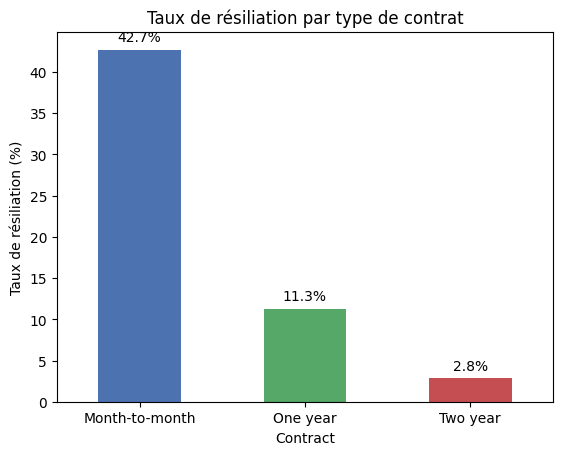

In [61]:
order = ["Month-to-month", "One year", "Two year"]
ax = contract_churn[order].plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"])
plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par type de contrat")
plt.xticks(rotation=0)

# Ajout des pourcentages au-dessus de chaque barre
for i, valeur in enumerate(contract_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")

plt.show()

Les abonnés en contrat mensuel résilient le plus (42,7 %, contre 2,8 % en biannuel, soit 39,9 points d'écart). C'est un problème, car un client perdu coûte environ 5 fois plus cher à remplacer qu'à retenir. Il faut proposer aux abonnés mensuels un avantage pour passer à un engagement annuel.

### Question 3 : Les abonnés fibre optique résilient-ils davantage ?

#### Étape 1 : nombre d'abonnés et taux de résiliation par service internet

In [62]:
print(df["InternetService"].value_counts())

# Taux de résiliation (%) pour chaque service
internet_churn = df.groupby("InternetService")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(internet_churn.round(1))

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64


Les abonnés fibre optique résilient à 41,9 %, contre 19,0 % pour le DSL et 7,4 % pour les abonnés sans internet. La fibre est donc le service avec le taux de résiliation le plus élevé

#### Étape 2 : prix moyen de chaque service internet

In [63]:
df.groupby("InternetService")["MonthlyCharges"].mean().round(1)

,MonthlyCharges
InternetService,
DSL,58.1
Fiber optic,91.5
No,21.1


La fibre est nettement plus chère : 91,5 par mois en moyenne, contre 58,1 pour le DSL. Les abonnés fibre paient donc environ 33 de plus par mois

#### Étape 3 : graphique du taux de résiliation par service internet

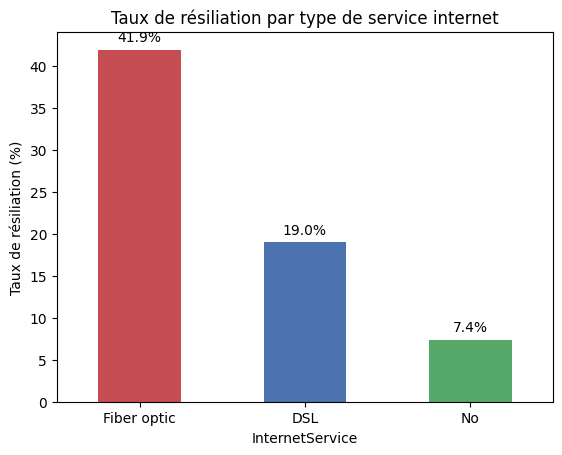

In [64]:
order = ["Fiber optic", "DSL", "No"]

# Diagramme en barres : une barre par service internet
ax = internet_churn[order].plot(kind="bar", color=["#C44E52", "#4C72B0", "#55A868"])

plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par type de service internet")
plt.xticks(rotation=0)   # noms des services à l'horizontale

# Pourcentage écrit au-dessus de chaque barre
for i, valeur in enumerate(internet_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")

plt.show()

La fibre optique a le taux de résiliation le plus élevé : 41,9 %, contre 19,0 % pour le DSL et 7,4 % pour les abonnés sans internet. La fibre est aussi le service le plus cher (91,5 par mois en moyenne, contre 58,1 pour le DSL). Je vérifie maintenant si cet écart vient seulement du type de contrat

#### Étape 4 : fibre et DSL comparés à type de contrat égal pour vérifier: « la fibre résilie plus, n’est-ce pas juste parce que ses abonnés sont plus souvent en contrat mensuel ? ».

In [77]:
# On retire les abonnés sans internet : on compare seulement DSL et fibre
avec_internet = df[df["InternetService"] != "No"]

# Tableau : une ligne par contrat, une colonne par service internet
# Chaque case = taux de résiliation (%)
tableau = avec_internet.pivot_table(
    index="Contract",
    columns="InternetService",
    values="Churn",
    aggfunc=lambda s: (s == "Yes").mean() * 100
)
print(tableau.round(1))

InternetService   DSL  Fiber optic
Contract                          
Month-to-month   32.2         54.6
One year          9.3         19.3
Two year          1.9          7.2


 La fibre résilie toujours plus que le DSL : 54,6 % contre 32,2 % en contrat mensuel, 19,3 % contre 9,3 % en annuel, 7,2 % contre 1,9 % en biannuel. L'écart n'est donc pas expliqué par le contrat seul.

**Hypothèse:** le prix plus élevé de la fibre (91,5 contre 58,1 par mois) et le manque de services d'accompagnement (sécurité en ligne, support technique). Pour les confirmer, il faudrait interroger les clients qui partent

In [79]:
# Part des abonnés en contrat mensuel, pour chaque service (en %)
part_mensuel = avec_internet.groupby("InternetService")["Contract"].apply(
    lambda s: (s == "Month-to-month").mean() * 100
)
print(part_mensuel.round(1))

InternetService
DSL            50.5
Fiber optic    68.7
Name: Contract, dtype: float64


68,7 % des abonnés fibre sont en contrat mensuel, contre 50,5 % des abonnés DSL. Les abonnés fibre sont donc plus souvent en contrat sans engagement, ce qui explique une partie de leur taux de résiliation élevé

### Question 2 : À quel moment (quelle ancienneté) le risque de résiliation est-il le plus fort ?

#### Étape 1 : créer les tranches d'ancienneté

In [65]:
bins = [-1, 6, 12, 24, 48, 72]
labels = ["0-6 mois", "7-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"]
df["tenure_bucket"] = pd.cut(df["tenure"], bins=bins, labels=labels)
df["tenure_bucket"].value_counts()

,count
tenure_bucket,
49-72 mois,2239
25-48 mois,1594
0-6 mois,1481
13-24 mois,1024
7-12 mois,705


Les abonnés sont répartis en 5 tranches d'ancienneté. Les plus nombreux sont les abonnés de plus de 4 ans (2 239), puis ceux de 25 à 48 mois (1 594). Les 6 premiers mois comptent 1 481 abonnés.

#### Étape 2 : taux de résiliation par tranche d'ancienneté

In [66]:
# Taux de résiliation (%) dans chaque tranche d'ancienneté
# groupby : on sépare les abonnés par tranche
# (s=="Yes").mean()*100 : part d'abonnés partis, en pourcentage
# observed=True : on ne garde que les tranches qui existent
tenure_churn = df.groupby("tenure_bucket", observed=True)["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(tenure_churn.round(1))

tenure_bucket
0-6 mois      52.9
7-12 mois     35.9
13-24 mois    28.7
25-48 mois    20.4
49-72 mois     9.5
Name: Churn, dtype: float64


Le taux de résiliation est le plus élevé dans les 6 premiers mois (52,9 %), puis il baisse à chaque tranche : 35,9 %, 28,7 %, 20,4 %, et seulement 9,5 % après 4 ans.

#### Visualisation : taux de résiliation par tranche d'ancienneté

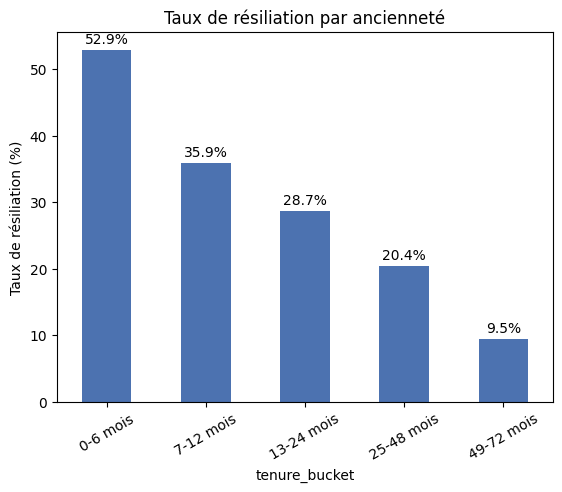

In [67]:
order = ["0-6 mois", "7-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"]
ax = tenure_churn[order].plot(kind="bar", color="#4C72B0")
plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par ancienneté")
plt.xticks(rotation=30)
for i, valeur in enumerate(tenure_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")
plt.show()

Le risque de départ est maximal dans les 6 premiers mois : 52,9 % des abonnés de cette tranche ont résilié. Il baisse ensuite régulièrement jusqu'à 9,5 % après 4 ans. La période critique est donc le début de l'abonnement.
**Recommandation :** concentrer les actions de rétention sur les nouveaux abonnés (suivi à l'inscription, contact après quelques semaines).

### Question 4 : Quel profil type combine les facteurs de risque, et combien d'abonnés représente-t-il ?

#### Étape 1 : filtrer le profil à risque

In [68]:
# On garde les abonnés qui ont les 4 critères en même temps (& = ET)
profile_mask = (
    (df["Contract"] == "Month-to-month")        # contrat sans engagement
    & (df["InternetService"] == "Fiber optic")  # fibre optique
    & (df["OnlineSecurity"] == "No")            # sans sécurité en ligne
    & (df["TechSupport"] == "No")               # sans support technique
)

# On applique le filtre : on ne garde que ces abonnés
profile = df[profile_mask]

# Combien sont-ils, et combien ont résilié ?
print(f"Abonnés du profil             : {len(profile)}  ({len(profile) / len(df):.1%} du parc)")
print(f"Taux de résiliation du profil : {(profile['Churn'] == 'Yes').mean():.1%}")

Abonnés du profil             : 1524  (21.6% du parc)
Taux de résiliation du profil : 60.7%


Le profil à risque (contrat mensuel, fibre optique, sans sécurité en ligne, sans support technique) regroupe 1 524 abonnés, soit 21,6 % du parc. Leur taux de résiliation est de 60,7 %, plus du double de la moyenne globale (26,5 %)

#### Étape 2 : abonnés du profil encore actifs et revenu mensuel menacé

In [69]:
# Parmi les abonnés du profil, ceux qui n'ont pas encore résilié
actifs = profile[profile["Churn"] == "No"]

# Leur facture mensuelle totale = revenu qu'on risque de perdre
revenu_menace = actifs["MonthlyCharges"].sum()

print(f"Abonnés du profil encore actifs : {len(actifs)}")
print(f"Revenu mensuel menacé           : {revenu_menace:,.0f} par mois")

Abonnés du profil encore actifs : 599
Revenu mensuel menacé           : 50,640 par mois


Sur les 1 524 abonnés du profil, 925 ont déjà résilié et 599 sont encore clients. Leur facturation mensuelle totale est de 50 640 : c'est le revenu à protéger en priorité

Abonnés déja partis

In [70]:
print(f"Abonnés du profil déjà partis   : {len(profile) - len(actifs)}")

Abonnés du profil déjà partis   : 925


#### Conclusion de la Question 4

Le profil type à risque est un abonné en contrat mensuel, à la fibre optique, sans sécurité en ligne ni support technique. Il représente 1 524 abonnés, soit 21,6 % du parc, avec un taux de résiliation de 60,7 % (contre 26,5 % en moyenne).

Parmi eux, 599 sont encore clients et paient ensemble 50 640 par mois : c'est le revenu à protéger en priorité.

Donc il faut concentrer le budget de rétention sur ces 599 abonnés, par exemple en leur proposant un engagement annuel avec la sécurité en ligne et le support technique inclus.

Ces résultats montrent des associations, pas des causes. On ne peut pas affirmer que la fibre ou l'absence de support provoque la résiliation.

## Analyse comparative : taux de résiliation selon le profil de l'abonné

Étape 1 : mode de paiement

In [71]:
paiement_churn = df.groupby("PaymentMethod")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(paiement_churn.round(1))

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn, dtype: float64


Les abonnés qui paient par chèque électronique résilient à 45,3 %, contre 15 à 19 % pour les autres modes de paiement.

Étape 2 : les 4 autres caractéristiques

#### Personnes âgées (senior)

In [72]:
senior_churn = df.groupby("SeniorCitizen")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(senior_churn.round(1))

SeniorCitizen
No     23.6
Yes    41.7
Name: Churn, dtype: float64


#### Abonnés en couple

In [73]:
partner_churn = df.groupby("Partner")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(partner_churn.round(1))

Partner
No     33.0
Yes    19.7
Name: Churn, dtype: float64


#### Abonnés avec personnes à charge

In [74]:
dependents_churn = df.groupby("Dependents")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(dependents_churn.round(1))

Dependents
No     31.3
Yes    15.5
Name: Churn, dtype: float64


#### Genre

In [75]:
genre_churn = df.groupby("gender")["Churn"].apply(lambda s: (s=="Yes").mean()*100)
print(genre_churn.round(1))

gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64


Les seniors résilient davantage (41,7 % contre 23,6 %), ainsi que les abonnés sans conjoint (33,0 % contre 19,7 %) et sans personnes à charge (31,3 % contre 15,5 %). Le genre ne change presque rien (26,9 % contre 26,2 %) : ce n'est pas un facteur de résiliation

Étape 3 : graphique du mode de paiement

#### Visualisation : taux de résiliation par mode de paiement

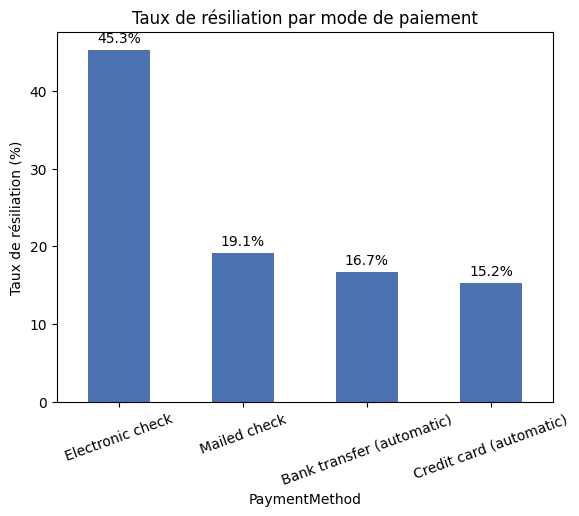

In [76]:
# Du plus élevé au plus faible
order = paiement_churn.sort_values(ascending=False).index

ax = paiement_churn[order].plot(kind="bar", color="#4C72B0")
plt.ylabel("Taux de résiliation (%)")
plt.title("Taux de résiliation par mode de paiement")
plt.xticks(rotation=20)

# Pourcentage écrit au-dessus de chaque barre
for i, valeur in enumerate(paiement_churn[order]):
    plt.text(i, valeur + 1, f"{valeur:.1f}%", ha="center")

plt.show()

Le chèque électronique se détache nettement : 45,3 % de résiliation, soit près de 3 fois plus que la carte bancaire (15,2 %). Les trois autres modes de paiement sont entre 15 et 19 %.

**Prudence :** c'est une association. Les abonnés au chèque électronique sont peut-être aussi plus souvent en contrat mensuel, ce qui expliquerait une partie de l'écart.

Synthèse finale

## Synthèse : réponses aux 4 questions métier

| Question | Réponse chiffrée |
|---|---|
| 1. Le contrat est-il le facteur dominant ? | Oui. Résiliation de 42,7 % en mensuel contre 2,8 % en biannuel : 39,9 points d'écart. |
| 2. À quelle ancienneté le risque est-il maximal ? | Les 6 premiers mois : 52,9 % de résiliation, puis baisse jusqu'à 9,5 % après 4 ans. |
| 3. La fibre optique résilie-t-elle davantage ? | Oui : 41,9 % contre 19,0 % (DSL). Hypothèse : la fibre est plus chère (91,5 contre 58,1 par mois). |
| 4. Quel profil à risque ? | Contrat mensuel + fibre + sans sécurité en ligne + sans support : 1 524 abonnés (21,6 %), 60,7 % de résiliation. |

**Revenu menacé :** 599 abonnés du profil sont encore clients, pour 50 640 par mois.

**Analyse comparative :** le chèque électronique (45,3 %), les seniors (41,7 %) et les abonnés sans conjoint ni personnes à charge résilient davantage. Le genre n'a pas d'effet.

**Recommandations :**
1. Proposer aux abonnés mensuels un avantage pour passer à un engagement annuel.
2. Suivre de près les nouveaux abonnés pendant les 6 premiers mois.
3. Offrir sécurité en ligne et support technique aux abonnés fibre.

**Limites :** ces résultats montrent des associations, pas des causes. La fibre est peut-être liée au prix plutôt qu'au service lui-même